In [1]:
import pandas as pd
import numpy as np
import pylab as plt
import glob
import matplotlib as mpl
import matplotlib.pyplot as plt



In [2]:
PFILES=glob.glob('../predictions_wrt_targets/*parquet')
pf_dict={i.split('/')[-1].replace('.parquet','').replace('PREDICTIONS_AFSTD',''):pd.read_csv(i)\
         .groupby('months').median().reset_index()\
         .drop('patient_id',axis=1)\
         .set_index('months') 
         for i in PFILES}
df = pd.concat(
    [v.add_suffix(f"_{k}") for k, v in pf_dict.items()],
    axis=1
)

<Axes: xlabel='months'>

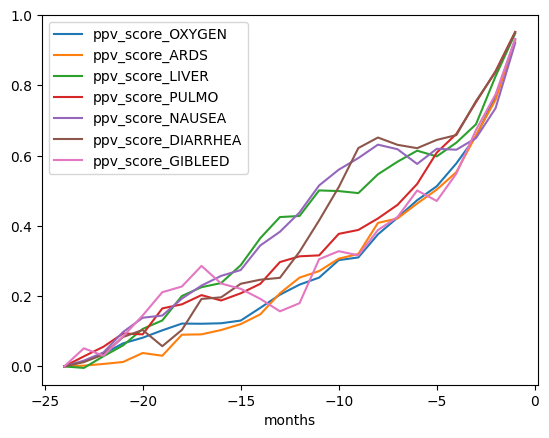

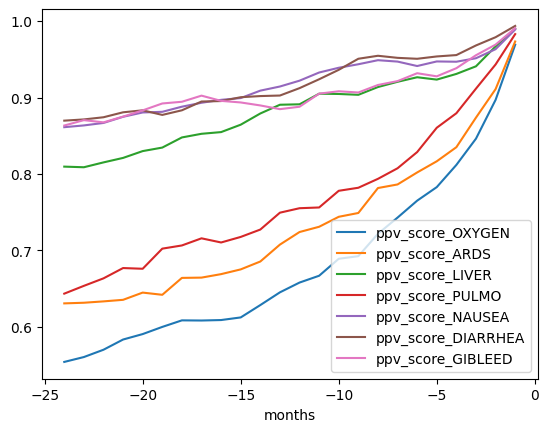

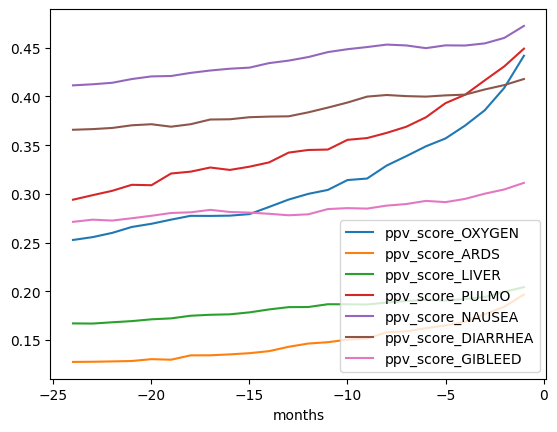

In [27]:
dfn=(df-df.loc[-24,:])
dfn=dfn/dfn.loc[-1,:]
dfnx=df/df.loc[-1,:]
ppvcols=[x for x in dfn.columns if 'ppv' in x]
dfn[ppvcols].ewm(alpha=.7).mean().plot()
dfnx[ppvcols].ewm(alpha=.7).mean().plot()    
df[ppvcols].ewm(alpha=.7).mean().plot()    


In [4]:
ppvcols

['ppv_score_OXYGEN',
 'ppv_score_ARDS',
 'ppv_score_LIVER',
 'ppv_score_PULMO',
 'ppv_score_NAUSEA',
 'ppv_score_DIARRHEA',
 'ppv_score_GIBLEED']

In [6]:
import glob
from math import sqrt

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Load and aggregate prediction files
# ------------------------------------------------------------
PFILES = glob.glob("../predictions_wrt_targets/*parquet")

pf_dict = {
    i.split("/")[-1]
        .replace(".parquet", "")
        .replace("PREDICTIONS_AFSTD", ""):
        pd.read_csv(i)
        .groupby("months").median()
        .reset_index()
        .drop("patient_id", axis=1)
        .set_index("months")
    for i in PFILES
}

df = pd.concat(
    [v.add_suffix(f"_{k}") for k, v in pf_dict.items()],
    axis=1
)


# ------------------------------------------------------------
# 2. Normalize curves
# ------------------------------------------------------------
dfn = (df - df.loc[-24, :])
dfn = dfn / dfn.loc[-1, :]

dfnx = df / df.loc[-1, :]

ppvcols = [c for c in dfnx.columns if "ppv" in c]


# ------------------------------------------------------------
# 3. Define Npos per event
# ------------------------------------------------------------
# Example:
# Npos_map = {
#     "ppv_score_ARDS": 14000,
#     "ppv_score_OXYGEN": 16000,
#     "ppv_score_PULMO": 12000,
# }

In [7]:
Npos_map = {
        'ppv_score_PULMO': 25986,
    'ppv_score_OXYGEN': 18369,
    'ppv_score_ARDS': 14066,
    'ppv_score_LIVER': 22572,
    'ppv_score_NAUSEA': 61884,
    'ppv_score_GIBLEED': 3410,
    'ppv_score_DIARRHEA': 49092,
}

In [8]:
# ------------------------------------------------------------
# 4. Build single DataFrame with CI columns
# ------------------------------------------------------------
def build_curve_with_ci(curve_df, npos_map, z=1.96):
    """
    Construct a single table containing normalized PPV curves
    and their binomial confidence intervals.

    CI model:
        Var(p) = p (1 - p) / n
    """
    print(curve_df.columns)
    out = pd.DataFrame(index=curve_df.index)

    for col in curve_df.columns:

        if col not in npos_map:
            raise KeyError(f"Missing Npos for column: {col}")

        n = float(npos_map[col])

        p = curve_df[col].astype(float)

        se = np.sqrt(np.maximum(p * (1.0 - p) / n, 0.0))

        lo = np.clip(p - z * se, 0.0, 1.0)
        hi = np.clip(p + z * se, 0.0, 1.0)

        out[col] = p
        out[col + "_lower"] = lo
        out[col + "_upper"] = hi

    return out


# ------------------------------------------------------------
# 5. Generate table
# ------------------------------------------------------------
dfnx_ppv = dfnx[ppvcols]

df_with_ci = build_curve_with_ci(
    curve_df=dfnx_ppv,
    npos_map=Npos_map,
    z=1.96
)

df_with_ci = df_with_ci.reset_index()


# ------------------------------------------------------------
# 6. Write single CSV
# ------------------------------------------------------------
OUTPUT_FILE = "normalized_ppv_curves_with_ci.csv"

df_with_ci.to_csv(
    OUTPUT_FILE,
    index=False,
    float_format="%.6f"
)

print("Wrote:", OUTPUT_FILE)

Index(['ppv_score_OXYGEN', 'ppv_score_ARDS', 'ppv_score_LIVER',
       'ppv_score_PULMO', 'ppv_score_NAUSEA', 'ppv_score_DIARRHEA',
       'ppv_score_GIBLEED'],
      dtype='str')
Wrote: normalized_ppv_curves_with_ci.csv


In [10]:
pfx_dict = {
    i.split("/")[-1]
        .replace(".parquet", "")
        .replace("PREDICTIONS_AFSTD", ""):
        pd.read_csv(i)
    for i in PFILES
}

In [11]:
pfx_dict.keys()

dict_keys(['OXYGEN', 'ARDS', 'LIVER', 'PULMO', 'NAUSEA', 'DIARRHEA', 'GIBLEED'])

In [14]:
pa=pfx_dict['ARDS']

In [20]:
pid=pa.patient_id.value_counts().index.values

In [33]:
pa[pa.patient_id==pid[15]]

,patient_id,months,predicted_risk,ppv_score
15,2.874867e+10,-24,0.046377,0.070018
553,2.874867e+10,-23,0.046377,0.070018
1106,2.874867e+10,-22,0.051560,0.113566
1673,2.874867e+10,-21,0.049308,0.098461
2250,2.874867e+10,-20,0.071861,0.218851
2841,2.874867e+10,-19,0.072497,0.221460
3444,2.874867e+10,-18,0.071245,0.215888
4062,2.874867e+10,-17,0.069286,0.205984
4696,2.874867e+10,-16,0.072795,0.222966
5344,2.874867e+10,-15,0.080033,0.259185


In [34]:
!./getmonth.py  --pfile ../predictions_wrt_targets/PREDICTIONS_AFSTDARDS.parquet    --event ARDS     --npos 14000     --risk 0.3

Event: ARDS
Month estimate: -1.0
Month CI: (-1.0, -1.0)
PPV: 0.3
PPV CI: (0.29240895264143346, 0.3075910473585665)
n: 14000
Norm constant: 0.2021278642870893
